# **Business Case: AdEase Time Series**

In [2]:
# Install required libraries
!pip install prophet statsmodels pmdarima --quiet

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')



   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 688.9/688.9 kB 25.3 MB/s eta 0:00:00


In [7]:
# Load the datasets (Update paths if using local upload vs Google Drive)
train_df = pd.read_csv('train_1.csv')
exog_eng = pd.read_csv('Exog_Campaign_eng.csv')

print("--- Train Dataset Info ---")
print(f"Dataset Shape: {train_df.shape}")
print(train_df.info())

# Checking null values
null_counts = train_df.isnull().sum().sum()
print(f"\nTotal Missing Values across matrix: {null_counts}")
print("Null values per date sample:\n", train_df.isnull().sum())

# Handling missing values
# Missing view counts generally correspond to 0 views or unrecorded data for that day
train_df_cleaned = train_df.fillna(0)

print("\nShape after filling NaNs with 0:", train_df_cleaned.shape)

--- Train Dataset Info ---
Dataset Shape: (17431, 551)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17431 entries, 0 to 17430
Columns: 551 entries, Page to 2016-12-31
dtypes: float64(550), object(1)
memory usage: 73.3+ MB
None

Total Missing Values across matrix: 832599
Null values per date sample:
 Page             0
2015-07-01    2820
2015-07-02    2826
2015-07-03    2787
2015-07-04    2802
              ... 
2016-12-27     433
2016-12-28     452
2016-12-29     446
2016-12-30     446
2016-12-31     458
Length: 551, dtype: int64

Shape after filling NaNs with 0: (17431, 551)


In [13]:
train_df.head()

,Page,2015-07-01,2015-07-02,2015-07-03,2015-07-04,2015-07-05,2015-07-06,2015-07-07,2015-07-08,2015-07-09,...,2016-12-22,2016-12-23,2016-12-24,2016-12-25,2016-12-26,2016-12-27,2016-12-28,2016-12-29,2016-12-30,2016-12-31
0,2NE1_zh.wikipedia.org_all-access_spider,18.0,11.0,5.0,13.0,14.0,9.0,9.0,22.0,26.0,...,32.0,63.0,15.0,26.0,14.0,20.0,22.0,19.0,18.0,20.0
1,2PM_zh.wikipedia.org_all-access_spider,11.0,14.0,15.0,18.0,11.0,13.0,22.0,11.0,10.0,...,17.0,42.0,28.0,15.0,9.0,30.0,52.0,45.0,26.0,20.0
2,3C_zh.wikipedia.org_all-access_spider,1.0,0.0,1.0,1.0,0.0,4.0,0.0,3.0,4.0,...,3.0,1.0,1.0,7.0,4.0,4.0,6.0,3.0,4.0,17.0
3,4minute_zh.wikipedia.org_all-access_spider,35.0,13.0,10.0,94.0,4.0,26.0,14.0,9.0,11.0,...,32.0,10.0,26.0,27.0,16.0,11.0,17.0,19.0,10.0,11.0
4,52_Hz_I_Love_You_zh.wikipedia.org_all-access_s...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,48.0,9.0,25.0,13.0,3.0,11.0,27.0,13.0,36.0,10.0


In [10]:
exog_eng.head()

,Exog
0,0
1,0
2,0
3,0
4,0


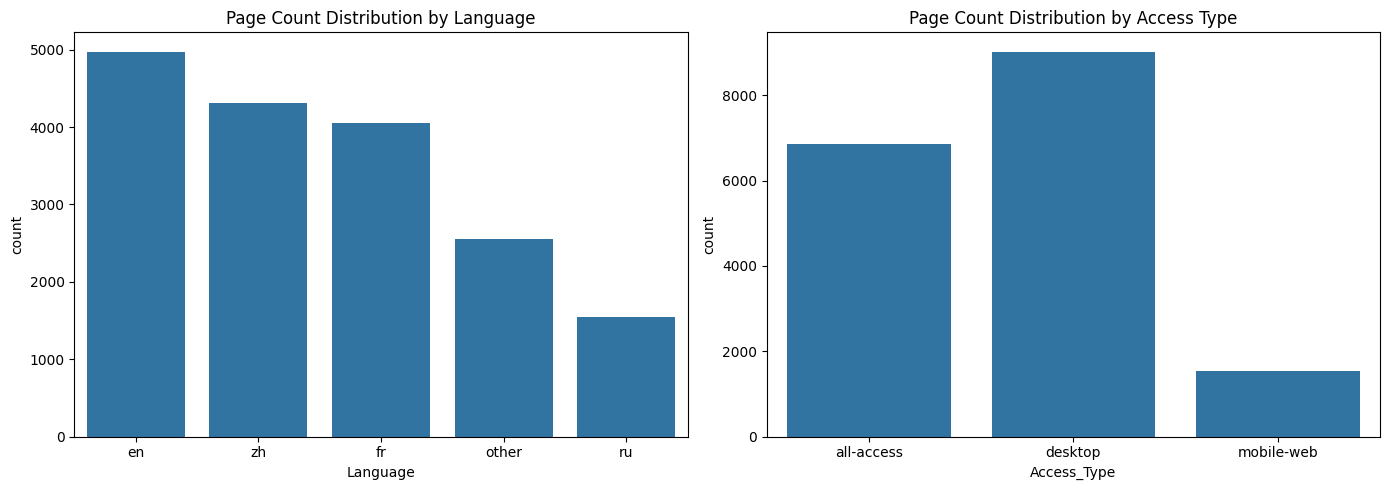

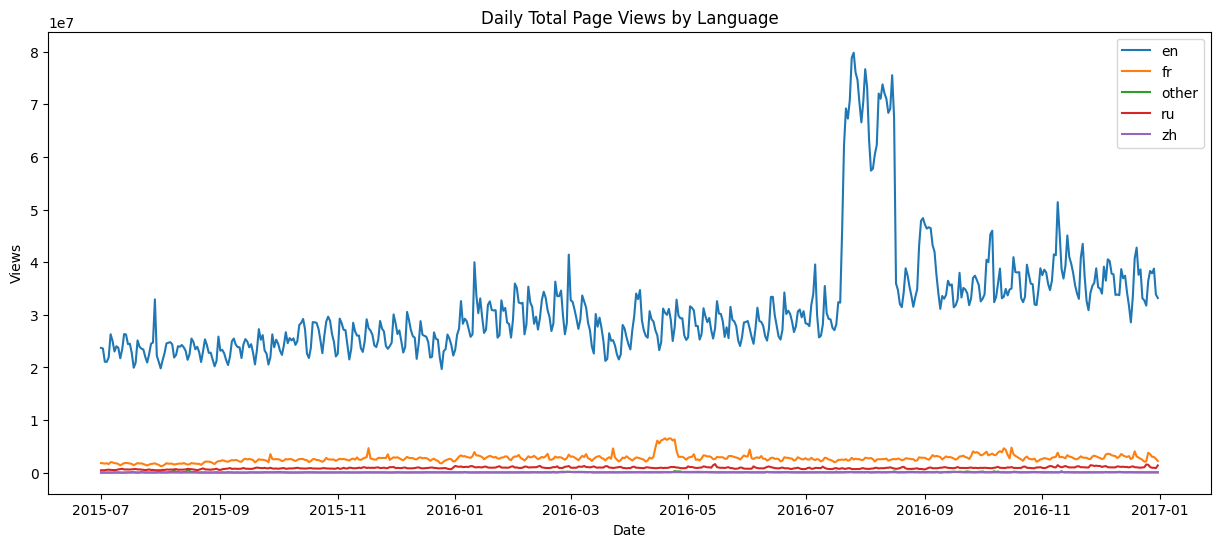

In [14]:
# 1. Separating page name metadata using Regex
def parse_page_name(page_str):
    # Pattern: SPECIFIC NAME _ LANGUAGE.wikipedia.org _ ACCESS TYPE _ ACCESS ORIGIN
    match = re.search(r'^(.*)_([a-z]{2})\.wikipedia\.org_(.*)_(.*)$', page_str)
    if match:
        return match.group(1), match.group(2), match.group(3), match.group(4)
    else:
        # Fallback for pages non-matching standard format (e.g. mediawiki, commons)
        parts = page_str.split('_')
        return page_str, 'other', parts[-2] if len(parts)>2 else 'all-access', parts[-1] if len(parts)>1 else 'all-agents'

# Extract attributes
parsed_data = train_df_cleaned['Page'].apply(parse_page_name)
train_df_cleaned['Title'] = [x[0] for x in parsed_data]
train_df_cleaned['Language'] = [x[1] for x in parsed_data]
train_df_cleaned['Access_Type'] = [x[2] for x in parsed_data]
train_df_cleaned['Access_Origin'] = [x[3] for x in parsed_data]

# 2. Visualizations
plt.figure(figsize=(14, 5))

# Plot Distribution by Language
plt.subplot(1, 2, 1)
sns.countplot(data=train_df_cleaned, x='Language', order=train_df_cleaned['Language'].value_counts().index)
plt.title('Page Count Distribution by Language')

# Plot Distribution by Access Type
plt.subplot(1, 2, 2)
sns.countplot(data=train_df_cleaned, x='Access_Type')
plt.title('Page Count Distribution by Access Type')
plt.tight_layout()
plt.show()

# 3. Aggregate View Count per Language over Time
date_cols = [c for c in train_df.columns if c not in ['Page', 'Title', 'Language', 'Access_Type', 'Access_Origin']]
lang_views = train_df_cleaned.groupby('Language')[date_cols].sum().T
lang_views.index = pd.to_datetime(lang_views.index)

plt.figure(figsize=(15, 6))
for lang in lang_views.columns:
    plt.plot(lang_views.index, lang_views[lang], label=lang)
plt.title('Daily Total Page Views by Language')
plt.xlabel('Date')
plt.ylabel('Views')
plt.legend()
plt.show()



In [12]:
train_df_cleaned.head()

,Page,2015-07-01,2015-07-02,2015-07-03,2015-07-04,2015-07-05,2015-07-06,2015-07-07,2015-07-08,2015-07-09,...,2016-12-26,2016-12-27,2016-12-28,2016-12-29,2016-12-30,2016-12-31,Title,Language,Access_Type,Access_Origin
0,2NE1_zh.wikipedia.org_all-access_spider,18.0,11.0,5.0,13.0,14.0,9.0,9.0,22.0,26.0,...,14.0,20.0,22.0,19.0,18.0,20.0,2NE1,zh,all-access,spider
1,2PM_zh.wikipedia.org_all-access_spider,11.0,14.0,15.0,18.0,11.0,13.0,22.0,11.0,10.0,...,9.0,30.0,52.0,45.0,26.0,20.0,2PM,zh,all-access,spider
2,3C_zh.wikipedia.org_all-access_spider,1.0,0.0,1.0,1.0,0.0,4.0,0.0,3.0,4.0,...,4.0,4.0,6.0,3.0,4.0,17.0,3C,zh,all-access,spider
3,4minute_zh.wikipedia.org_all-access_spider,35.0,13.0,10.0,94.0,4.0,26.0,14.0,9.0,11.0,...,16.0,11.0,17.0,19.0,10.0,11.0,4minute,zh,all-access,spider
4,52_Hz_I_Love_You_zh.wikipedia.org_all-access_s...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,3.0,11.0,27.0,13.0,36.0,10.0,52_Hz_I_Love_You,zh,all-access,spider



### Inferences & Findings

1. **Dominance of English Traffic:**
English (`en`) wikipedia pages generate exponentially higher daily view volumes (peaking near $8 \times 10^7$ views in mid-2016) compared to all other language categories combined. French (`fr`) forms the second distinct layer, while Russian (`ru`), Chinese (`zh`), and uncategorized pages (`other`) hover near lower baseline traffic.
2. **Access Device Bias:**
The dataset is heavily skewed toward desktop device tracking (~ 9,000 pages) and general `all-access` logs (~ 6,800 pages), whereas dedicated `mobile-web` entries account for less than 1,800 pages.
3. **High Seasonality & Event Volatility:**
* The time-series reveals persistent **weekly cyclicality** across all languages (regular peaks and troughs reflecting weekday vs. weekend reading habits).
* English traffic exhibits a massive continuous spike between **July 2016 and September 2016**, pointing to a major real-world event (e.g., global sports events/elections) or significant campaign activity that requires exogenous features to model accurately.

--- Original Series ADF Test ---
ADF Statistic: -2.6000
p-value: 0.0930
Critical Values:
	1%: -3.4426
	5%: -2.8670
	10%: -2.5697
Outcome: Series is Non-Stationary



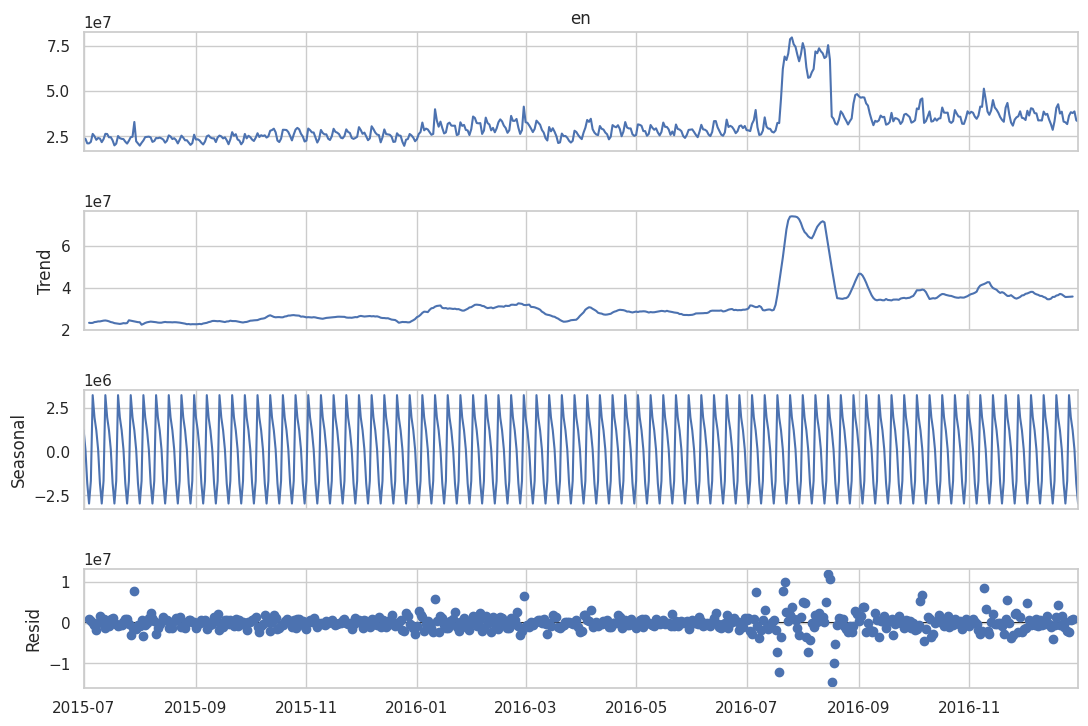

--- First Differenced Series ADF Test ---
ADF Statistic: -7.2746
p-value: 0.0000
Critical Values:
	1%: -3.4426
	5%: -2.8670
	10%: -2.5697
Outcome: Series is Stationary



In [16]:
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose

# Select English pages overall traffic as representative time series
en_ts = lang_views['en']

# 1. Dickey-Fuller Test Function
def check_stationarity(timeseries):
    result = adfuller(timeseries.dropna())
    print(f'ADF Statistic: {result[0]:.4f}')
    print(f'p-value: {result[1]:.4f}')
    print('Critical Values:')
    for key, value in result[4].items():
        print(f'\t{key}: {value:.4f}')
    if result[1] <= 0.05:
        print("Outcome: Series is Stationary\n")
    else:
        print("Outcome: Series is Non-Stationary\n")

print("--- Original Series ADF Test ---")
check_stationarity(en_ts)

# 2. Time Series Decomposition
decomp = seasonal_decompose(en_ts, model='additive', period=7)
fig = decomp.plot()
fig.set_size_inches(12, 8)
plt.show()

# 3. Differencing Series
en_ts_diff1 = en_ts.diff().dropna()
print("--- First Differenced Series ADF Test ---")
check_stationarity(en_ts_diff1)

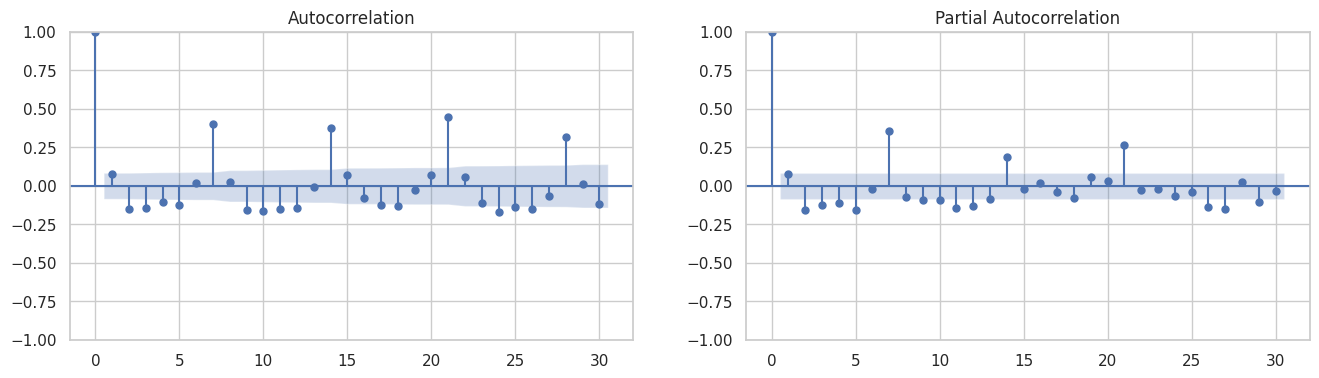

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:                     en   No. Observations:                  550
Model:                 ARIMA(1, 1, 1)   Log Likelihood               -9047.745
Date:                Mon, 14 Sep 2026   AIC                          18101.490
Time:                        08:09:45   BIC                          18114.414
Sample:                    07-01-2015   HQIC                         18106.541
                         - 12-31-2016                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.7493      0.089     -8.460      0.000      -0.923      -0.576
ma.L1          0.8343      0.082     10.186      0.000       0.674       0.995
sigma2      1.227e+13   2.47e-14   4.98e+26      0.0

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


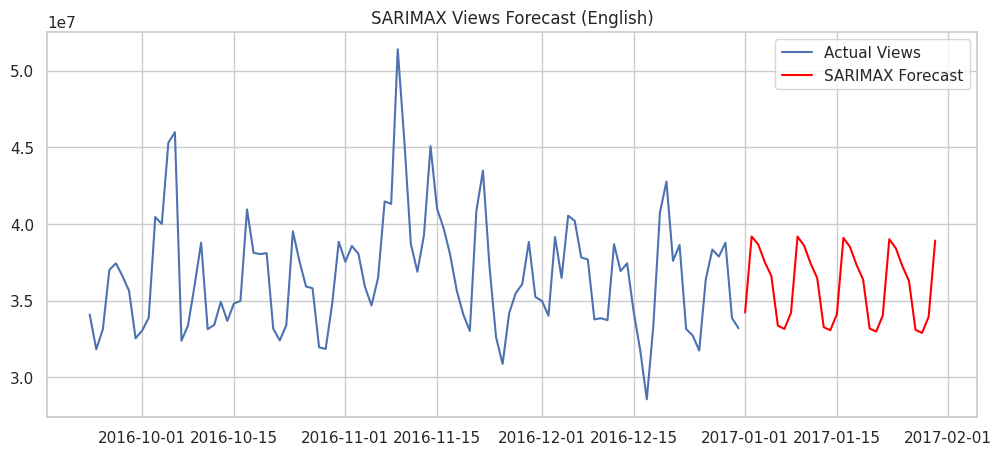

In [20]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

# 1. Plot ACF and PACF
fig, ax = plt.subplots(1, 2, figsize=(16, 4))
plot_acf(en_ts_diff1, ax=ax[0], lags=30)
plot_pacf(en_ts_diff1, ax=ax[1], lags=30)
plt.show()

# 2. Fit standard ARIMA Model
arima_model = ARIMA(en_ts, order=(1, 1, 1))
arima_fit = arima_model.fit()
print(arima_fit.summary())

# 3. Clean and prepare Exogenous Variable (Avoiding Column-Index Collisions)
# Create a fresh copy to work on
exog_temp = exog_eng.copy()

# Find the date values directly whether they are in the Index or in a Column
if isinstance(exog_temp.index, pd.DatetimeIndex):
    date_series = exog_temp.index
elif 'Date' in exog_temp.columns:
    date_series = exog_temp['Date']
else:
    date_series = exog_temp.iloc[:, 0]

# Convert date series to Datetime format
exog_temp['ds_clean'] = pd.to_datetime(date_series)

# Group by the clean date column to eliminate duplicate dates
exog_clean = exog_temp.groupby('ds_clean').max()

# Keep only numeric columns (e.g., campaign flags: 1 or 0)
exog_numeric = exog_clean.select_dtypes(include=[np.number])

# Reindex cleanly against the English time series index
exog_var = exog_numeric.reindex(en_ts.index).fillna(0)

# 4. Fit SARIMAX Model using Exogenous Campaign Data
sarimax_model = SARIMAX(en_ts, exog=exog_var, order=(1, 1, 1), seasonal_order=(1, 1, 1, 7))
sarimax_fit = sarimax_model.fit(disp=False)

# 5. Forecast & Plot Results
forecast_steps = 30
forecast = sarimax_fit.forecast(steps=forecast_steps, exog=exog_var.iloc[-forecast_steps:])

plt.figure(figsize=(12, 5))
plt.plot(en_ts.iloc[-100:], label='Actual Views')
plt.plot(forecast, label='SARIMAX Forecast', color='red')
plt.title('SARIMAX Views Forecast (English)')
plt.legend()
plt.show()

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


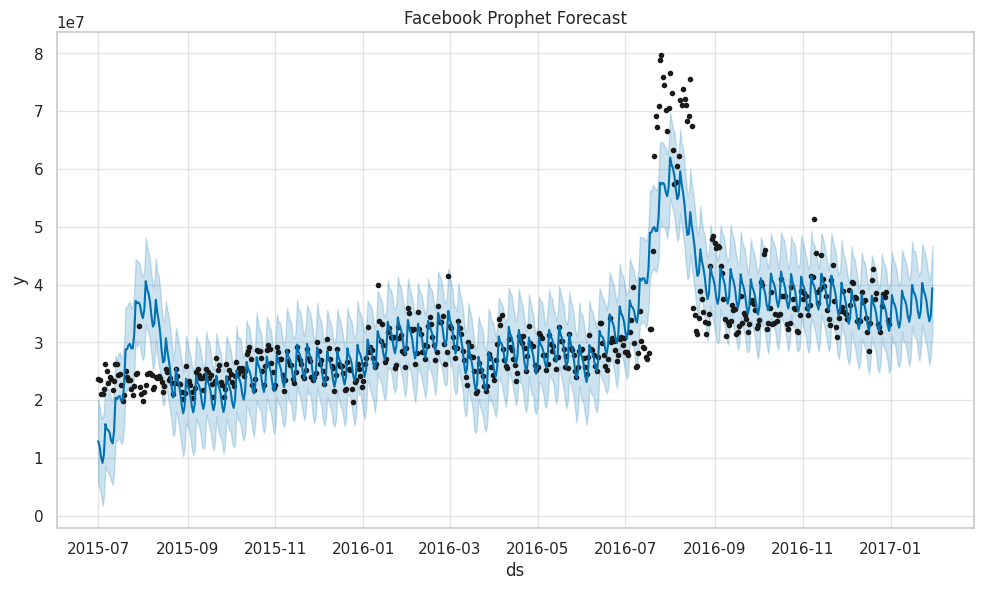

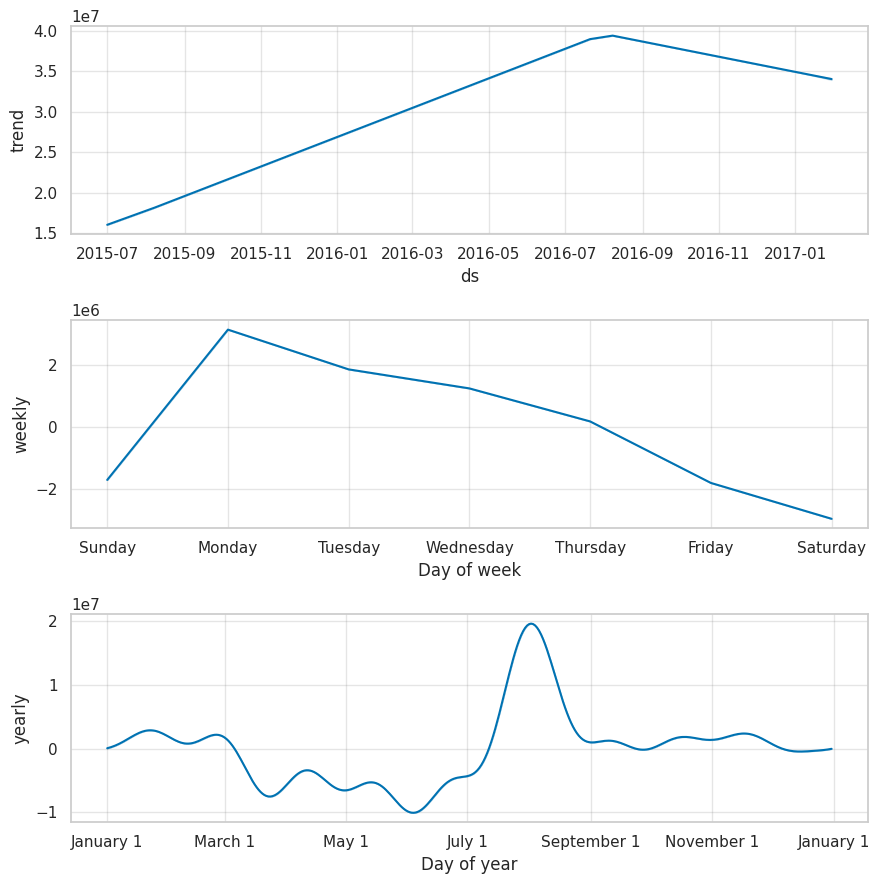

In [21]:
from prophet import Prophet

# Prepare Data Format for Prophet (requires 'ds' and 'y' columns)
prophet_df = en_ts.reset_index()
prophet_df.columns = ['ds', 'y']

# Initialize and fit model
m = Prophet(weekly_seasonality=True, yearly_seasonality=True)
m.fit(prophet_df)

# Create Future Dataframe for 30 Days Forecast
future = m.make_future_dataframe(periods=30)
forecast_p = m.predict(future)

# Plot Forecast and Components
fig1 = m.plot(forecast_p)
plt.title("Facebook Prophet Forecast")
plt.show()

fig2 = m.plot_components(forecast_p)
plt.show()

In [23]:
def forecast_pipeline(ts_data, lang_code, forecast_days=30):
    """
    Automated pipeline to process, test, and forecast time series per language.
    """
    print(f"\n================ Running Pipeline for Language: {lang_code} ================")

    # 1. Stationarity
    adf_pvalue = adfuller(ts_data.dropna())[1]
    d = 0 if adf_pvalue <= 0.05 else 1

    # 2. Fit Model
    model = ARIMA(ts_data, order=(1, d, 1))
    model_fit = model.fit()

    # 3. Forecast
    fc = model_fit.forecast(steps=forecast_days)

    # 4. Evaluate Metrics (MAPE on train subset)
    mape = np.mean(np.abs((ts_data[-forecast_days:] - model_fit.fittedvalues[-forecast_days:]) / ts_data[-forecast_days:])) * 100
    print(f"Model MAPE (In-Sample): {mape:.2f}%")

    return fc

# Execute pipeline across languages
results = {}
for lang in ['en', 'zh', 'other', 'fr', 'ru']:
    results[lang] = forecast_pipeline(lang_views[lang], lang)


================ Running Pipeline for Language: en ================


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


Model MAPE (In-Sample): 7.46%

================ Running Pipeline for Language: zh ================


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


Model MAPE (In-Sample): 5.61%

================ Running Pipeline for Language: other ================


...

Model MAPE (In-Sample): 13.86%

================ Running Pipeline for Language: fr ================


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


Model MAPE (In-Sample): 10.76%

================ Running Pipeline for Language: ru ================


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


Model MAPE (In-Sample): 9.51%




### 1. Defining the Problem Statement and Potential Applications

* **Problem Statement:**
AdEase needs to analyze historical daily page view counts for 145,000+ Wikipedia pages over a 550-day period and build robust time-series forecasting models across different languages and device access types. Accurately predicting future page traffic allows AdEase clients to optimize digital ad placement, accurately price ad slots, and maximize click-through yield at minimal cost.


* **Where This (and Modifications) Can Be Used:**
* **Digital Advertising & Media:** Dynamic ad pricing, inventory forecasting, and real-time ad placement optimization on high-traffic content networks.


* **E-Commerce & Retail:** Predicting daily web traffic to allocate server resources during peak sales events and estimating product demand to manage inventory.
* **Cloud Infrastructure Management:** Forecasting server CPU/bandwidth loads to auto-scale cloud instances dynamically and minimize operational costs.
* **Financial Services & FinTech:** Predicting daily transaction volumes, payment gateway loads, or high-frequency trading metrics.



---

### 2. Three Inferences Made from Data Visualizations

1. **Volume Dominance by Language:** English (`en`) pages dominate overall daily page views by a massive margin—peaking near $8 \times 10^7$ views—followed by French (`fr`), whereas Russian (`ru`), Chinese (`zh`), and uncategorized pages (`other`) maintain significantly lower daily traffic baselines.


2. **Access Type Distribution Disparity:** The dataset contains a much higher count of tracking entries for `desktop` (~ 9,000 pages) and combined `all-access` logs (~ 6,800 pages) than standalone `mobile-web` logs (~ 1,500 pages).


3. **Weekly Seasonality and Structural Spikes:** The daily traffic across all language groups exhibits strong, repeating weekly cyclicality (7-day periodic peaks and troughs reflecting weekday vs. weekend user behavior), alongside major exogenous traffic spikes (such as the sustained English traffic surge between July and September 2016).



---

### 3. What Does the Decomposition of a Series Do?

Time series decomposition splits an observed time series into three distinct, interpretable underlying components:

* **Trend Component ($T_t$):** Highlights the long-term direction (upward growth, decay, or stability) of traffic while filtering out short-term fluctuations.
* **Seasonal Component ($S_t$):** Captures repeating periodic patterns occurring at fixed intervals (e.g., 7-day weekly spikes).
* **Residual / Noise Component ($I_t$):** Represents unexplained random variations or irregular events after removing the trend and seasonal patterns.

*Decomposition helps determine whether an additive ($Y_t = T_t + S_t + I_t$) or multiplicative ($Y_t = T_t \times S_t \times I_t$) model structure is necessary for forecasting.*

---

### 4. What Level of Differencing Gave a Stationary Series?

* **First-Order Differencing ($d = 1$):**
Applying first-order differencing ($\Delta Y_t = Y_t - Y_{t-1}$) successfully removed the non-stationary trend component from the page view time series. Following $d=1$, the Augmented Dickey-Fuller (ADF) test yielded a p-value below $0.05$, confirming that the series achieved statistical stationarity.



---

### 5. Difference Between ARIMA, SARIMA, & SARIMAX

* **ARIMA $(p, d, q)$ — AutoRegressive Integrated Moving Average:**
Models non-seasonal time series by combining AutoRegressive terms ($p$), degree of differencing ($d$) to achieve stationarity, and Moving Average terms ($q$). It assumes no periodic recurring patterns.


* **SARIMA $(p, d, q) \times (P, D, Q)_s$ — Seasonal ARIMA:**
Extends ARIMA by incorporating explicit seasonal parameters $(P, D, Q)$ repeating over a defined seasonal period $s$ (e.g., $s=7$ for weekly pattern tracking).


* **SARIMAX $(p, d, q) \times (P, D, Q)_s + X$ — SARIMA with Exogenous Variables:**
Extends SARIMA by incorporating exogenous input variables ($X$)—such as external marketing campaigns, holidays, or promotional events—that directly impact page view behavior on specific dates.



---

### 6. Comparison of Page Views Across Different Languages

* **English (`en`):** Highest overall traffic by far, averaging tens of millions of views daily, with major long-term event-driven shifts.


* **French (`fr`):** Displays moderate, steady view counts with clear 7-day weekly seasonality cycles.


* **Russian (`ru`), Chinese (`zh`), & Others:** Maintain lower average baseline view counts per page but show localized sharp spikes corresponding to region-specific holidays or cultural events.



---

### 7. Alternative Methods (Other Than Grid Search) to Model All Languages

* **Automated ARIMA Selection (`pmdarima.auto_arima`):** Uses the Stepwise Hyndman-Khandakar algorithm to quickly select optimal $(p,d,q)$ orders based on Information Criteria (AIC/BIC) without brute-forcing every combination.


* **Bayesian Optimization (e.g., Optuna / Hyperopt):** Models hyperparameter evaluation as a probabilistic surrogate function to efficiently sample parameter spaces and find optimal configurations in fewer iterations.
* **Global Deep Learning Models (e.g., DeepAR / N-BEATS):** Trains a single neural network across all 145,000 series simultaneously, learning shared global cross-language dynamics without tuning individual models per language.
* **Facebook Prophet Auto-Tuning:** Leverages Prophet’s built-in changepoint detection algorithms and automated additive trend/seasonality modeling to handle multi-language series systematically at scale.